<a href="https://colab.research.google.com/github/Violetaaa/tfg-learning/blob/main/02_langGraph.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
!apt-get install graphviz -y
!pip install -q langgraph langchain-openai langchain-community langchain-google-genai pygraphviz

from langgraph.graph import StateGraph, END
from typing import TypedDict, Annotated
import operator
from langchain_core.messages import AnyMessage, SystemMessage, HumanMessage, ToolMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_community.tools.tavily_search import TavilySearchResults

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
graphviz is already the newest version (2.42.2-9ubuntu0.1).
0 upgraded, 0 newly installed, 0 to remove and 2 not upgraded.


In [2]:
import os
from google.colab import userdata

os.environ["TAVILY_API_KEY"] = userdata.get('TAVILY_API_KEY')

tool = TavilySearchResults(max_results=4)
print(type(tool))
print(tool.name)

<class 'langchain_community.tools.tavily_search.tool.TavilySearchResults'>
tavily_search_results_json


/tmp/ipykernel_7994/2461503839.py:6: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tool = TavilySearchResults(max_results=4) #increased number of results


In [7]:
class AgentState(TypedDict):
    messages: Annotated[list[AnyMessage], operator.add]

In [8]:
class Agent:

    def __init__(self, model, tools, system=""):
        self.system = system
        graph = StateGraph(AgentState)
        graph.add_node("llm", self.call_openai)
        graph.add_node("action", self.take_action)
        graph.add_conditional_edges(
            "llm",
            self.exists_action,
            {True: "action", False: END}
        )
        graph.add_edge("action", "llm")
        graph.set_entry_point("llm")
        self.graph = graph.compile()
        self.tools = {t.name: t for t in tools}
        self.model = model.bind_tools(tools)

    def exists_action(self, state: AgentState):
        result = state['messages'][-1]
        return len(result.tool_calls) > 0

    def call_openai(self, state: AgentState):
        messages = state['messages']
        if self.system:
            messages = [SystemMessage(content=self.system)] + messages
        message = self.model.invoke(messages)
        return {'messages': [message]}

    def take_action(self, state: AgentState):
        tool_calls = state['messages'][-1].tool_calls
        results = []
        for t in tool_calls:
            print(f"Calling: {t}")
            if not t['name'] in self.tools:      # check for bad tool name from LLM
                print("\n ....bad tool name....")
                result = "bad tool name, retry"  # instruct LLM to retry if bad
            else:
                result = self.tools[t['name']].invoke(t['args'])
            results.append(ToolMessage(tool_call_id=t['id'], name=t['name'], content=str(result)))
        print("Back to the model!")
        return {'messages': results}

In [27]:
from google import genai
client = genai.Client(api_key=os.environ["GOOGLE_API_KEY"])
for m in client.models.list():
    if "flash" in m.name:
        print(m.name)

models/gemini-2.5-flash
models/gemini-2.5-flash-preview-tts
models/gemini-flash-latest
models/gemini-flash-lite-latest
models/gemini-2.5-flash-lite
models/gemini-2.5-flash-image
models/gemini-3-flash-preview
models/gemini-3.1-flash-lite-preview
models/gemini-3.1-flash-lite
models/gemini-3.1-flash-image-preview
models/gemini-3.1-flash-image
models/gemini-3.1-flash-lite-image
models/gemini-3.5-flash
models/gemini-3.5-flash-lite
models/gemini-omni-flash-preview
models/gemini-omni-1.1-flash
models/gemini-3.6-flash
models/gemini-3.7-flash
models/gemini-3.8-flash
models/gemini-3.1-flash-tts-preview
models/gemini-3.8-flash-tts
models/gemini-3.8-flash-lite-tts
models/gemini-2.5-flash-native-audio-latest
models/gemini-2.5-flash-native-audio-preview-09-2025
models/gemini-2.5-flash-native-audio-preview-12-2025
models/gemini-3.1-flash-live-preview


In [28]:
MODEL = "gemini-3.5-flash"

In [29]:
import os
from google.colab import userdata

os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')

prompt = """You are a smart research assistant. Use the search engine to look up information. \
You are allowed to make multiple calls (either together or in sequence). \
Only look up information when you are sure of what you want. \
If you need to look up some information before asking a follow up question, you are allowed to do that!
"""

model = ChatGoogleGenerativeAI(model=MODEL)
abot = Agent(model, [tool], system=prompt)

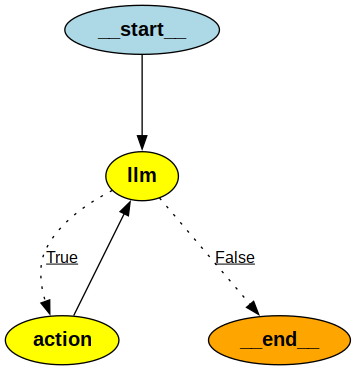

In [30]:
from IPython.display import Image

Image(abot.graph.get_graph().draw_png())

In [39]:
messages = [HumanMessage(content="What is the current stock price of Apple")]
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'AAPL stock price current'}, 'id': 'call_240932', 'type': 'tool_call'}
Back to the model!


In [40]:
result

{'messages': [HumanMessage(content='What is the current stock price of Apple', additional_kwargs={}, response_metadata={}),
  AIMessage(content=[], additional_kwargs={'function_call': {'name': 'tavily_search_results_json', 'arguments': '{"query": "AAPL stock price current"}'}, '__gemini_function_call_thought_signatures__': {'call_240932': 'EsgECsUEAWkUfRNGvAkEeAwX575iqhG6OI4+Pxtyy6jwJ9jgSq+YE2d+M8SmmbR1mpqOT5+KlJ+S5F+idJ8qvcjjCAGHivCTd4Re+WMI0ppIq/ZOWcjHCtnEJYKLTapOSyOnJ24/TviGxVWgTkjPbf1XRgiZ0ZV4hQ/YQhKMFmF7XUeuNDKQzFjgONkmUKAVCNK3P+o7m3NDcJzq+qRwTARSEOXdViTpd4Wxs9Kt/mGd7RgPPIUVi9xWmx5m1xhghkwPSbkokSOxDgKQIK6dejI0npHBjt3LJS0Z7G8GVkyXp1r1rlr3tkkgFLHi0onT8x9ZtxCB7YCBbQmkwT1qXHRQZ5vqW+lEMKshS60W2cHr4ooDcSolLCyjj7qAa+VsK86XyQqYHCpYW15CAhk7q0i/ANavy7lBXJWY0Rv/qRI+HPho2qNHQxCCQNsxtECJ5WqiXgUI6gCb16uEaOYmsvwwW6L7inA1mFXgQgUiQPLoGWQ/jlRwIuxyIqsxcIXGLkT8Os+R2/JfmkB7JB+elyUyjQbkING4qlNf/fttgXrkLAsH+spJd1rZ4CauEisIjy9khEcMRNJWkI9+wAHMul0NPrDDKbiGKibvP0V5a4u8E8cqlRmHt1xBtqzMpFSXJGswhGhDQj1mAi5dzv

In [41]:
result['messages'][-1].content

[{'type': 'text',
  'text': "I'm unable to retrieve the current stock price for Apple (AAPL) right now because my real-time search tool is currently experiencing a technical issue (unauthorized access error). \n\nTo get the most accurate and up-to-the-minute stock price, please check a financial platform such as:\n* [Google Finance (AAPL)](https://www.google.com/finance/quote/AAPL:NASDAQ)\n* [Yahoo Finance (AAPL)](https://finance.yahoo.com/quote/AAPL)\n* [Bloomberg](https://www.bloomberg.com/quote/AAPL:US)",
  'extras': {'signature': 'EtgJCtUJAWkUfRMT0fnMQhEXCE0hHn+sojFvoxddLSQ/vMPKuLkzc3J2Txfr8JAltlsECCawkCsf6xKiHet1XFNG2htYYR6dwCXC81++iPYlU8yLqY0UxQPasM/7XRtAqnYD2uDLUsb1+vQ6KowbRIC1cbHTjrnVvdA4ymRpU9uGuDX0nLAOs/l/SobwJ7EwEGyURWQfCMC8c2ZpB6Ne+8HGUjG4nmgKTdwNzfUNYxSHwdNM6w71mP9UFleGKiRA+VYn/vt5L14tdpv8IX2nkkwXD3KSzhEbwebjh8s16Uu1E0pSF1lOBnnVSMmwrxi8/Ahar3NjCBO2z4s3+GiumZriO+82NUO6Shp5W3KT4oXfLVKFUWns3Fv5M/yN5ufy4ncacZGBfMrPbeo8D8KUqiSeceLliXZ0rIU99J5EgQDeGRONx/bT1Bn860mWI8qvCKqI0COmayy

In [42]:
messages = [HumanMessage(content="What is the current stock price of Apple and Microsoft?")]
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'AAPL MSFT stock price today'}, 'id': 'call_237709', 'type': 'tool_call'}
Back to the model!


In [43]:
result['messages'][-1].content

[{'type': 'text',
  'text': "I'm sorry, but I am currently unable to retrieve the real-time stock prices for Apple (AAPL) and Microsoft (MSFT) due to a technical issue with my search tool. \n\nTo get the most accurate, up-to-the-minute stock prices, you can check financial tracking websites such as:\n* [Google Finance](https://www.google.com/finance) (Search for **AAPL** and **MSFT**)\n* [Yahoo Finance](https://finance.yahoo.com/)\n* [Bloomberg](https://www.bloomberg.com/)",
  'extras': {'signature': 'EqsJCqgJAWkUfROXCfDdxN50S7l1iRofUgLf/JznrRtB2A0dBBdo+KSLtC6j+Pc2ZE7sMpizJauah+YbacMlCqy9lkkiq0TKiTu3KzooV+T5i2SGPEs8x2Xye8e5GRekO1DTFj1FkOF4aK42iu4gMZLO4EuX3HsslAockYdsn0K9SlWZAawZZy2hpaFktoY3po9Q9PUdr69IdNCPjy9XzPuLAaURFVwwxcYXl7mqPo2oYHZAKNE01N01ezs/wP13x3l/++H49xJWMApbC0AdiY8KOKLcvwD0Kdjc7YRixuDhQJJ4VNZ1feyf5xBk4Xpj3RMiu++FsTh6LFvSQkjSaNeVRH5Uh0F2k6yebkFuu2v5NrmwLEGP5H3NLlowimIaYWaSqgG+ykTBJNCez3wYHZ/uPdH3CBVzP8WvQE8fdf7t5I8qcKf1U9kCC0OtzVBFuabcEd5Sc/ibr5oDNh9wrXlmp4rnKVBVrBxrprN2bZIBW

In [33]:
# Note, the query was modified to produce more consistent results.
# Results may vary per run and over time as search information and models change.

query = "Who won the super bowl in 2024? In what state is the winning team headquarters located? \
What is the GDP of that state? Answer each question."
messages = [HumanMessage(content=query)]

model = ChatGoogleGenerativeAI(model=MODEL)
abot = Agent(model, [tool], system=prompt)
result = abot.graph.invoke({"messages": messages})

Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'who won the super bowl in 2024'}, 'id': 'call_221832', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'where are the kansas city chiefs headquarters located state'}, 'id': 'call_221833', 'type': 'tool_call'}
Calling: {'name': 'tavily_search_results_json', 'args': {'query': 'GDP of Missouri 2023 2024'}, 'id': 'call_221834', 'type': 'tool_call'}
Back to the model!


In [36]:
print(result['messages'][-1].content)

[{'type': 'text', 'text': "Based on the official records and economic data:\n\n1. **Who won the Super Bowl in 2024?**\nThe **Kansas City Chiefs** won Super Bowl LVIII (58) on February 11, 2024, defeating the San Francisco 49ers with a score of 25–22 in overtime.\n\n2. **In what state is the winning team's headquarters located?**\nThe Kansas City Chiefs' headquarters and training facilities (located at the Truman Sports Complex alongside GEHA Field at Arrowhead Stadium) are located in Kansas City, **Missouri**. \n\n3. **What is the GDP of that state?**\nAccording to the U.S. Bureau of Economic Analysis (BEA), Missouri's Gross Domestic Product (GDP) reached an annualized rate of approximately **$422.3 billion** in the first quarter of 2024 (up from approximately $389 billion to $400 billion in late 2022/2023).", 'extras': {'signature': 'EpMVCpAVAWkUfRN2FGu3NE3ClauN8J2yb/PJKLcjebgHYdowjb0rqhNN+2gUN0qOPm179vY1y++mZ3VEjhWqOu/0vrlf/BgsnyvlEJvZ36H7TYK3rVY1c9w/zDEcyl+nRNJ1bvqTZJoP94lHTqwykHBBi